# Analysis of the results

## 1. Data Loading

In [1]:
import pandas as pd
import pyarrow.parquet as pq

# PARQUET_FILE = "data/solver_results.parquet"
PARQUET_FILE = "data/solver_results_forcing_base_10.parquet"

# Just metadata - very fast, no data load
pf = pq.ParquetFile(PARQUET_FILE)
print(pf.schema)              # schema with types
print(pf.metadata)            # row count, row groups, size
print(pf.metadata.num_rows)

# Read only specific columns
# df = pq.read_table(PARQUET_FILE, columns=['col1', 'col2']).to_pandas()

required group field_id=-1 schema {
  optional binary field_id=-1 id (String);
  optional binary field_id=-1 prompt (String);
  optional binary field_id=-1 answer (String);
  optional binary field_id=-1 solver_answer (String);
  optional boolean field_id=-1 solver_correct;
  optional binary field_id=-1 solver_strategy (String);
  optional binary field_id=-1 category (String);
  optional binary field_id=-1 ops_mapping (String);
  optional binary field_id=-1 digits_mapping (String);
  optional binary field_id=-1 solver_tier (String);
  optional double field_id=-1 solver_radix;
  optional binary field_id=-1 ops_candidates (String);
  optional binary field_id=-1 equations (String);
}

  created_by: parquet-cpp-arrow version 24.0.0
  num_columns: 13
  num_rows: 823
  num_row_groups: 1
  format_version: 2.6
  serialized_size: 9041
823


In [2]:
df = pq.read_table(PARQUET_FILE).to_pandas()
df

,id,prompt,answer,solver_answer,solver_correct,solver_strategy,category,ops_mapping,digits_mapping,solver_tier,solver_radix,ops_candidates,equations
0,00457d26,"In Alice's Wonderland, a secret set of transfo...",@&,@&,True,standard,arithmetic,"{""*"": ""mul_p1"", ""-"": ""absdiff""}","{""`"": 5, ""!"": 6, ""["": 4, ""{"": 9, ""'"": 2, ""\"""":...",full,10.0,"{""*"": [""mul_p1""], ""-"": [""absdiff"", ""rsub_signe...","[{""type"": ""example"", ""lhs"": {""l0"": ""`"", ""l1"": ..."
1,00c032a8,"In Alice's Wonderland, a secret set of transfo...",\^?,\^?,True,little_endian,arithmetic,"{""!"": ""mul"", ""]"": ""add"", ""<"": ""absdiff""}","{""}"": 5, ""`"": 4, ""?"": 2, ""("": 7, "")"": 1, ""#"": ...",full,10.0,"{""!"": [""mul""], ""]"": [""add""], ""<"": [""absdiff"", ...","[{""type"": ""example"", ""lhs"": {""l0"": ""}"", ""l1"": ..."
2,012cab1f,"In Alice's Wonderland, a secret set of transfo...",|@{,|@{,True,little_endian,arithmetic,"{""'"": ""add"", "">"": ""absdiff"", ""]"": ""mul""}","{""`"": 7, ""("": 9, ""&"": 6, "":"": 8, ""%"": 2, ""@"": ...",full,10.0,"{""'"": [""add""], "">"": [""absdiff"", ""rsub_signed""]...","[{""type"": ""example"", ""lhs"": {""l0"": ""`"", ""l1"": ..."
3,0133bcec,"In Alice's Wonderland, a secret set of transfo...",\([#,\([#,True,pure_concat,concatenation,NaN,NaN,NaN,NaN,NaN,"[{""type"": ""example"", ""lhs"": {""l0"": ""%"", ""l1"": ..."
4,017a871e,"In Alice's Wonderland, a secret set of transfo...",\:,\:,True,little_endian,arithmetic,"{""-"": ""absdiff_m2"", ""+"": ""add_p2"", ""*"": ""a2_pl...","{""#"": 2, ""]"": 6, ""\\"": 3, ""\"""": 7, ""!"": 8, ""^""...",full,10.0,"{""-"": [""absdiff_m2""], ""+"": [""add_p2""], ""*"": [""...","[{""type"": ""example"", ""lhs"": {""l0"": ""#"", ""l1"": ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
818,fdbdf50c,"In Alice's Wonderland, a secret set of transfo...","-\""","-\""",True,little_endian,arithmetic,"{""-"": ""sub_signed"", ""}"": ""add"", ""("": ""mul""}","{""%"": 0, ""?"": 8, "")"": 9, ""\\"": 3, ""^"": 1, ""]"":...",full,10.0,"{""-"": [""sub_signed""], ""}"": [""add""], ""("": [""mul""]}","[{""type"": ""example"", ""lhs"": {""l0"": ""%"", ""l1"": ..."
819,fe6da79d,"In Alice's Wonderland, a secret set of transfo...",:&]!,:&]!,True,standard,arithmetic,"{""-"": ""neg_absdiff"", ""*"": ""mul"", ""+"": ""concat_...","{""\\"": 9, ""&"": 5, "":"": 1, ""$"": 3, ""}"": 8, ""#"":...",full,10.0,"{""-"": [""neg_absdiff""], ""*"": [""mul""], ""+"": [""co...","[{""type"": ""example"", ""lhs"": {""l0"": ""\\"", ""l1"":..."
820,ff0e37ae,"In Alice's Wonderland, a secret set of transfo...","%'""`","%'""`",True,pure_concat,concatenation,NaN,NaN,NaN,NaN,NaN,"[{""type"": ""example"", ""lhs"": {""l0"": ""?"", ""l1"": ..."
821,ff121f08,"In Alice's Wonderland, a secret set of transfo...",#<,#<,True,standard,arithmetic,"{""+"": ""sub_signed"", ""("": ""mul"", ""\\"": ""add_p1""}","{""%"": 4, ""`"": 8, ""^"": 7, ""<"": 2, ""#"": 1, ""!"": ...",full,10.0,"{""+"": [""sub_signed""], ""("": [""mul"", ""lcm""], ""\\...","[{""type"": ""example"", ""lhs"": {""l0"": ""%"", ""l1"": ..."


In [3]:
df['solver_tier'].unique()

<ArrowStringArray>
['full', nan]
Length: 2, dtype: str

In [4]:
df['solver_strategy'].value_counts()

solver_strategy
standard         432
little_endian    297
pure_concat       75
Name: count, dtype: int64

In [5]:
df['category'].value_counts(dropna=False)

category
arithmetic       729
concatenation     75
NaN               19
Name: count, dtype: int64

## 2. Sample Inspection

In [6]:
test = df[df['id'] == '1cce5949']#
test

,id,prompt,answer,solver_answer,solver_correct,solver_strategy,category,ops_mapping,digits_mapping,solver_tier,solver_radix,ops_candidates,equations
98,1cce5949,"In Alice's Wonderland, a secret set of transfo...",[?},[?},True,little_endian,arithmetic,"{""}"": ""rsub_signed"", ""/"": ""mul"", ""-"": ""add""}","{""$"": 7, ""?"": 5, ""%"": 3, ""`"": 2, ""]"": 1, ""\"""":...",full,10.0,"{""}"": [""rsub_signed"", ""neg_absdiff""], ""/"": [""m...","[{""type"": ""example"", ""lhs"": {""l0"": ""$"", ""l1"": ..."


In [7]:
print(test['equations'].iloc[0])    

[{"type": "example", "lhs": {"l0": "$", "l1": "?", "op": "/", "r0": "%", "r1": "`"}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["]", "]", "%", "]"]}}, {"type": "example", "lhs": {"l0": "%", "l1": "$", "op": "/", "r0": "\"", "r1": "?"}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["$", "[", "%", ">"]}}, {"type": "example", "lhs": {"l0": "[", "l1": "?", "op": "-", "r0": "\\", "r1": "\""}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["\\", ">", "]"]}}, {"type": "example", "lhs": {"l0": "`", "l1": "]", "op": "/", "r0": "\\", "r1": ">"}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["`", "?", "?"]}}, {"type": "to_predict", "lhs": {"l0": "`", "l1": "\\", "op": "}", "r0": "`", "r1": "]"}, "rhs": {"op": "}", "sign_pos": "postfix", "actual_rhs": ["[", "?"]}}]


In [8]:
prompt= df[df['id'] == '1d15b7e6']['prompt']
print(prompt.iloc[0])

In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
^$)[^ = [^^{
^^?[" = {^(
![@({ = $$@
[}@{( = $^@
Now, determine the result for: |[)$[


In [9]:
df.iloc[0]['ops_candidates']

'{"*": ["mul_p1"], "-": ["absdiff", "rsub_signed"]}'

## 3. Dataset Overview

In [10]:
df['solver_strategy'].unique()

<ArrowStringArray>
['standard', 'little_endian', 'pure_concat', nan]
Length: 4, dtype: str

In [11]:
df['solver_radix'].unique()

array([10., nan])

## 4. Operation Frequency Analysis
Counts how often each operation is mapped (number of puzzles) and how often it appears across all equations (occurrences). Splits by solver mode (standard vs. little-endian) and computes sampling probabilities with temperature scaling.

In [12]:
import json
from collections import Counter
from src.solver_eq_symbolic import OP_NAME_TO_IDX

ALL_OPS = list(OP_NAME_TO_IDX.keys())  # canonical ops, index order

def count_ops(rows):
    mapping_counter = Counter()
    occurrence_counter = Counter()
    for _, row in rows.iterrows():
        ops_json = row['ops_mapping']
        if pd.isna(ops_json) if isinstance(ops_json, float) else ops_json is None:
            continue
        ops = json.loads(ops_json)  # {op_char: op_name}

        # Count per-equation occurrences from the stored equations JSON
        eq_counts = Counter()
        equations_json = row['equations']
        if equations_json and not (isinstance(equations_json, float) and pd.isna(equations_json)):
            try:
                for eq in json.loads(equations_json):
                    eq_counts[eq['lhs']['op']] += 1
            except Exception:
                pass

        for op_char, op_name in ops.items():
            mapping_counter[op_name] += 1
            occurrence_counter[op_name] += eq_counts.get(op_char, 0)

    return mapping_counter, occurrence_counter

# standard = big-endian mode; little_endian = reversed-digit mode
df_arith = df[df['solver_strategy'].isin(['standard', 'little_endian'])]
df_std   = df_arith[df_arith['solver_strategy'] == 'standard']
df_le    = df_arith[df_arith['solver_strategy'] == 'little_endian']

std_map,   std_occ   = count_ops(df_std)
le_map,    le_occ    = count_ops(df_le)
total_map, total_occ = count_ops(df_arith)

freq = pd.DataFrame({
    'operation':        ALL_OPS,
    'std_mapping':      [std_map.get(op, 0)   for op in ALL_OPS],
    'std_occurrence':   [std_occ.get(op, 0)   for op in ALL_OPS],
    'le_mapping':       [le_map.get(op, 0)    for op in ALL_OPS],
    'le_occurrence':    [le_occ.get(op, 0)    for op in ALL_OPS],
    'total_mapping':    [total_map.get(op, 0) for op in ALL_OPS],
    'total_occurrence': [total_occ.get(op, 0) for op in ALL_OPS],
}).sort_values('total_mapping', ascending=False).reset_index(drop=True)

print(f"Non-concat puzzles: {len(df_arith)}  (standard={len(df_std)}, little_endian={len(df_le)})")
print(f"Ops with zero mapping count: {(freq['total_mapping'] == 0).sum()} / {len(ALL_OPS)}")

with pd.option_context('display.max_rows', None):
    display(freq)

Non-concat puzzles: 729  (standard=432, little_endian=297)
Ops with zero mapping count: 0 / 22


,operation,std_mapping,std_occurrence,le_mapping,le_occurrence,total_mapping,total_occurrence
0,mul,189,382,206,414,395,796
1,add,165,341,192,368,357,709
2,sub_signed,143,285,115,253,258,538
3,absdiff,131,237,89,146,220,383
4,concat_fwd,109,183,1,1,110,184
5,add_m1,66,132,20,42,86,174
6,add_p1,55,107,30,57,85,164
7,mul_m1,69,129,15,34,84,163
8,mul_p1,65,125,16,35,81,160
9,rsub_signed,34,48,28,63,62,111


In [13]:
freq.sum()

operation           muladdsub_signedabsdiffconcat_fwdadd_m1add_p1m...
std_mapping                                                      1136
std_occurrence                                                   2173
le_mapping                                                        763
le_occurrence                                                    1511
total_mapping                                                    1899
total_occurrence                                                 3684
dtype: object

In [14]:
# Probability the issue is solved with an standard method
prob_std = freq['std_mapping'].sum() / freq['total_mapping'].sum() 
print(f"Probability of standard method solving the issue: {prob_std:.4f}")

# Probability the issue is solved with a little-endian method
prob_le = freq['le_mapping'].sum() / freq['total_mapping'].sum()
print(f"Probability of little-endian method solving the issue: {prob_le:.4f}")

Probability of standard method solving the issue: 0.5982
Probability of little-endian method solving the issue: 0.4018


In [15]:
#
filter_df = freq[(freq['total_mapping'] > 0) & (freq['total_occurrence'] > 0)]
filter_df = filter_df[['operation', 'total_mapping']]
filter_df

,operation,total_mapping
0,mul,395
1,add,357
2,sub_signed,258
3,absdiff,220
4,concat_fwd,110
5,add_m1,86
6,add_p1,85
7,mul_m1,84
8,mul_p1,81
9,rsub_signed,62


In [16]:
import numpy as np

## Calculate the probabilities accross the tototal mapping count and the total occurrence count. Use a temperature value
TEMPERATURE = 1.0
filter_df['mapping_prob_temp'] = filter_df['total_mapping']**(1/TEMPERATURE)
# filter_df['occurrence_prob_temp'] = filter_df['total_occurrence']**(1/TEMPERATURE)
filter_df['mapping_prob_temp'] /= filter_df['mapping_prob_temp'].sum()
# filter_df['occurrence_prob_temp'] /= filter_df['occurrence_prob_temp'].sum()

# TEMPERATURE = 0.7
# filter_df['mapping_prob_temp_exp'] = np.exp(filter_df['total_mapping'] / TEMPERATURE) / np.exp(filter_df['total_mapping'] / TEMPERATURE).sum()

filter_df

,operation,total_mapping,mapping_prob_temp
0,mul,395,0.208004
1,add,357,0.187994
2,sub_signed,258,0.135861
3,absdiff,220,0.115850
4,concat_fwd,110,0.057925
5,add_m1,86,0.045287
6,add_p1,85,0.044760
7,mul_m1,84,0.044234
8,mul_p1,81,0.042654
9,rsub_signed,62,0.032649


## 5. Radix / Base Distribution
Checks which numeric bases (radix) the solver uses across all puzzles.

In [17]:
# checking the radix frequency
df['solver_radix'].value_counts()

solver_radix
10.0    729
Name: count, dtype: int64

## 6. Equation & Symbol Extraction
Reconstructs the full equation set per puzzle (examples + query with answer) and counts unique symbols per sample.

In [18]:
import json
from src.parsing import content_symbols

df['equations'] = df['equations'].apply(
    lambda v: json.loads(v) if v and not (isinstance(v, float) and pd.isna(v)) else []
)
df['num_unique_symbols'] = df['equations'].apply(
    lambda eqs: len(content_symbols(eqs)) if eqs else 0
)

print(f"Sample equations for row 0:\n{df['equations'][0]}\n")
print(f"Unique symbol counts — min: {df['num_unique_symbols'].min()}, max: {df['num_unique_symbols'].max()}, mean: {df['num_unique_symbols'].mean():.2f}")
df[['id', 'equations', 'num_unique_symbols']].head(10)

Sample equations for row 0:
[{'type': 'example', 'lhs': {'l0': '`', 'l1': '!', 'op': '*', 'r0': '[', 'r1': '{'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ["'", '"', '[', '`']}}, {'type': 'example', 'lhs': {'l0': '\\', 'l1': "'", 'op': '*', 'r0': "'", 'r1': '>'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ['!', '[', '@']}}, {'type': 'example', 'lhs': {'l0': '\\', 'l1': "'", 'op': '-', 'r0': '!', 'r1': '`'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ['\\', '\\']}}, {'type': 'example', 'lhs': {'l0': '`', 'l1': '!', 'op': '*', 'r0': '\\', 'r1': '&'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ["'", '@', "'", '{']}}, {'type': 'to_predict', 'lhs': {'l0': '[', 'l1': '[', 'op': '-', 'r0': '!', 'r1': "'"}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ['@', '&']}}]

Unique symbol counts — min: 6, max: 10, mean: 9.56


,id,equations,num_unique_symbols
0,00457d26,"[{'type': 'example', 'lhs': {'l0': '`', 'l1': ...",10
1,00c032a8,"[{'type': 'example', 'lhs': {'l0': '}', 'l1': ...",10
2,012cab1f,"[{'type': 'example', 'lhs': {'l0': '`', 'l1': ...",10
3,0133bcec,"[{'type': 'example', 'lhs': {'l0': '%', 'l1': ...",9
4,017a871e,"[{'type': 'example', 'lhs': {'l0': '#', 'l1': ...",8
5,01b2aa67,"[{'type': 'example', 'lhs': {'l0': ':', 'l1': ...",9
6,01ef1e3e,"[{'type': 'example', 'lhs': {'l0': ''', 'l1': ...",10
7,022c4d73,"[{'type': 'example', 'lhs': {'l0': '/', 'l1': ...",9
8,02664ad5,"[{'type': 'example', 'lhs': {'l0': '`', 'l1': ...",10
9,02902eb3,"[{'type': 'example', 'lhs': {'l0': '!', 'l1': ...",9


## 7. Symbol Distribution Analysis
Analyzes how operator symbols are distributed across puzzles: frequency per symbol, per LHS position, and cross-position correlation.

<Axes: >

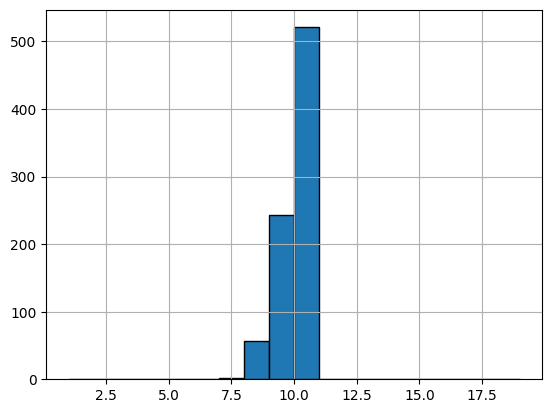

In [19]:
df['num_unique_symbols'].hist(bins=range(1, 20), edgecolor='black')

In [20]:

# Operator symbols: extract position-2 (middle of 5-char LHS) from every equation in every prompt
from collections import Counter

op_sym_counts = Counter()
total_equations = 0

for _, row in df.iterrows():
    for line in row['prompt'].split('\n'):
        if ' = ' not in line or line.startswith('Now'):
            continue
        lhs = line.split(' = ', 1)[0]
        # All LHS are 5 chars; operator is always at index 2
        if len(lhs) == 5:
            op_sym_counts[lhs[2]] += 1
            total_equations += 1

sym_df = pd.DataFrame(
    [(sym, cnt, round(cnt / total_equations * 100, 2))
     for sym, cnt in op_sym_counts.most_common()],
    columns=['operator_symbol', 'equation_count', 'pct_of_equations']
)

print(f"Total equations parsed: {total_equations}")
print(f"Unique operator symbols: {len(op_sym_counts)}\n")
with pd.option_context('display.max_rows', None):
    display(sym_df)


Total equations parsed: 3342
Unique operator symbols: 26



,operator_symbol,equation_count,pct_of_equations
0,*,771,23.07
1,-,759,22.71
2,+,752,22.50
3,),70,2.09
4,',64,1.92
5,},58,1.74
6,\,57,1.71
7,{,55,1.65
8,#,52,1.56
9,`,52,1.56


In [21]:

# Compare symbol frequency distribution across all 5 LHS positions
import numpy as np

pos_counts = [Counter() for _ in range(5)]
total = 0

for _, row in df.iterrows():
    for line in row['prompt'].split('\n'):
        if ' = ' not in line or line.startswith('Now'):
            continue
        lhs = line.split(' = ', 1)[0]
        if len(lhs) == 5:
            for i, ch in enumerate(lhs):
                pos_counts[i][ch] += 1
            total += 1

all_syms = sorted(set().union(*pos_counts))

rows = []
for i, c in enumerate(pos_counts):
    counts = [c.get(s, 0) for s in all_syms]
    top3 = ', '.join(f'{s}={n}' for s, n in c.most_common(3))
    rows.append({
        'position':    f'pos{i} (operator)' if i == 2 else f'pos{i}',
        'unique_syms': len(c),
        'min':         min(counts),
        'max':         max(counts),
        'std':         round(np.std(counts), 1),
        'top3':        top3,
    })

display(pd.DataFrame(rows))

# Pearson correlation between position frequency vectors
vecs = [np.array([c.get(s, 0) for s in all_syms], dtype=float) for c in pos_counts]
corr = np.array([[np.corrcoef(vecs[i], vecs[j])[0, 1] for j in range(5)] for i in range(5)])
corr_df = pd.DataFrame(corr,
                       index=[f'pos{i}' for i in range(5)],
                       columns=[f'pos{i}' for i in range(5)]).round(3)
print("\nPearson correlation between position frequency vectors:")
display(corr_df)


,position,unique_syms,min,max,std,top3
0,pos0,23,0,164,47.8,"$=164, [=162, ""=160"
1,pos1,23,0,161,47.8,"|=161, \=161, #=159"
2,pos2 (operator),26,32,771,228.5,"*=771, -=759, +=752"
3,pos3,23,0,164,47.6,"#=164, ?=160, {=158"
4,pos4,23,0,163,47.2,"[=163, }=162, `=156"



Pearson correlation between position frequency vectors:


,pos0,pos1,pos2,pos3,pos4
pos0,1.000,0.949,-0.974,0.935,0.961
pos1,0.949,1.000,-0.968,0.961,0.942
pos2,-0.974,-0.968,1.000,-0.974,-0.983
pos3,0.935,0.961,-0.974,1.000,0.955
pos4,0.961,0.942,-0.983,0.955,1.000


## 8. Operation-Symbol Mapping
Shows which operations get assigned to the three most common operator symbols (`*`, `+`, `-`) across all puzzles.

In [22]:

# Operations mapped to *, -, + across all samples
from collections import defaultdict
target_syms = ['*', '+', '-']

# Extend the target symb with the other symbols
for sym in sym_df['operator_symbol']:
    if sym not in target_syms:
        target_syms.append(sym)

op_map = defaultdict(Counter)  # sym -> {op_name: count}

for _, row in df.iterrows():
    if pd.isna(row['ops_mapping']):
        continue
    ops = json.loads(row['ops_mapping'])
    for sym, op_name in ops.items():
        if sym in target_syms:
            op_map[sym][op_name] += 1

# Build a wide table: rows = operation names, columns = symbols
all_ops = sorted(set(op for c in op_map.values() for op in c))
table = pd.DataFrame(
    {sym: [op_map[sym].get(op, 0) for op in all_ops] for sym in target_syms},
    index=all_ops
)
table.index.name = 'operation'
table['total'] = table.sum(axis=1)
table = table.sort_values('total', ascending=False)

print("Rows = operation name, Columns = operator symbol, Values = number of puzzles mapped")
display(table)


Rows = operation name, Columns = operator symbol, Values = number of puzzles mapped


,*,+,-,),',},\,{,#,`,...,>,?,"""",/,],%,^,$,[,total
operation,,,,,,,,,,,,,,,,,,,,,
mul,196,15,15,10,9,6,10,10,7,9,...,6,10,5,11,5,5,7,4,4,395
add,15,164,12,11,7,13,9,8,6,12,...,6,5,5,4,6,7,4,10,8,357
sub_signed,8,8,153,5,5,5,4,1,2,5,...,1,5,2,1,3,6,5,1,4,258
absdiff,8,10,139,3,5,1,1,6,8,2,...,1,5,1,1,3,3,2,2,1,220
concat_fwd,40,44,0,0,2,0,2,2,0,1,...,1,1,2,1,1,0,2,1,2,110
add_m1,2,67,3,1,1,2,0,0,0,1,...,0,0,1,0,0,0,0,1,2,86
add_p1,1,67,1,3,0,2,2,0,0,0,...,0,0,1,0,0,1,0,2,0,85
mul_m1,68,3,1,1,2,1,0,0,0,0,...,1,1,1,1,0,0,0,1,0,84
mul_p1,56,2,1,1,0,0,0,4,2,1,...,2,1,2,1,0,1,0,1,0,81


In [23]:
# Top 3 operations per symbol
top3_rows = []
for sym in target_syms:
    for op, cnt in op_map[sym].most_common(3):
        top3_rows.append({'symbol': sym, 'rank': op_map[sym].most_common().index((op, cnt)) + 1, 'operation': op, 'count': cnt})

top3_df = pd.DataFrame(top3_rows)
top3_pivot = top3_df.pivot_table(index=['rank', 'operation'], columns='symbol', values='count', fill_value=0)

# Simpler wide format: one row per (symbol, rank)
top3_wide = (
    top3_df
    .assign(label=top3_df['operation'] + ' (' + top3_df['count'].astype(str) + ')')
    .pivot(index='rank', columns='symbol', values='label')
    .fillna('')
)
top3_wide.columns.name = None
top3_wide.index.name = 'rank'

print("Top 3 operations per operator symbol (count in parentheses)")
display(top3_wide[target_syms])  # keep symbol column order


Top 3 operations per operator symbol (count in parentheses)


,*,+,-,),',},\,{,#,`,...,(,>,?,"""",/,],%,^,$,[
rank,,,,,,,,,,,,,,,,,,,,,
1,mul (196),add (164),sub_signed (153),add (11),mul (9),add (13),mul (10),mul (10),absdiff (8),add (12),...,mul (9),add (6),mul (10),mul (5),mul (11),add (6),add (7),mul (7),add (10),add (8)
2,mul_m1 (68),add_m1 (67),absdiff (139),mul (10),add (7),mul (6),add (9),add (8),mul (7),mul (9),...,sub_signed (6),mul (6),sub_signed (5),add (5),add (4),mul (5),sub_signed (6),sub_signed (5),mul (4),sub_signed (4)
3,mul_p1 (56),add_p1 (67),neg_absdiff (31),sub_signed (5),absdiff (5),sub_signed (5),sub_signed (4),absdiff (6),add (6),sub_signed (5),...,add (4),mul_p1 (2),add (5),gcd (2),rsub_signed (2),absdiff (3),mul (5),add (4),absdiff (2),mul (4)


## 9. Samples Where Operator Appears as Last Character of RHS
Filters puzzles that contain at least one equation where the operator symbol (LHS position 2) is also the last character of the RHS — e.g. `![@({ = $$@` where `@` is both the operator and the final RHS character. Query equations are checked separately.

In [24]:

def find_op_in_rhs_last(equations):
    matching = []
    for eq in equations:
        lhs = eq.get('lhs', {})
        rhs = eq.get('rhs', {})
        lhs_op = lhs.get('op', '') if isinstance(lhs, dict) else None
        rhs_op = rhs.get('op', '') if isinstance(rhs, dict) else None
        sign_pos = rhs.get('sign_pos', None) if isinstance(rhs, dict) else None

        if lhs_op and rhs_op and lhs_op == rhs_op and sign_pos == 'postfix':  #'prefix':
            matching.append(eq)
    return matching

df['op_in_rhs_last_eqs']    = df['equations'].apply(find_op_in_rhs_last)

mask_any = df['op_in_rhs_last_eqs'].apply(len) > 0

print(f"Samples with op-in-RHS-last in any equation : {mask_any.sum()}")

review_df = (
    df[mask_any][['id', 'op_in_rhs_last_eqs',
                  'solver_strategy', 'solver_tier', 'prompt', 'answer']]
    .reset_index(drop=True)
)
review_df[['id', 'op_in_rhs_last_eqs', 'solver_strategy', 'solver_tier']]

Samples with op-in-RHS-last in any equation : 23


,id,op_in_rhs_last_eqs,solver_strategy,solver_tier
0,1cce5949,"[{'type': 'to_predict', 'lhs': {'l0': '`', 'l1...",little_endian,full
1,1d15b7e6,"[{'type': 'example', 'lhs': {'l0': '!', 'l1': ...",little_endian,full
2,239771fb,"[{'type': 'example', 'lhs': {'l0': '$', 'l1': ...",little_endian,full
3,303c84ea,"[{'type': 'example', 'lhs': {'l0': ''', 'l1': ...",little_endian,full
4,48817fa0,"[{'type': 'example', 'lhs': {'l0': '&', 'l1': ...",little_endian,full
5,56efc838,"[{'type': 'example', 'lhs': {'l0': '>', 'l1': ...",little_endian,full
6,57f6878e,"[{'type': 'example', 'lhs': {'l0': '%', 'l1': ...",little_endian,full
7,71310176,"[{'type': 'example', 'lhs': {'l0': '^', 'l1': ...",little_endian,full
8,71d91445,"[{'type': 'example', 'lhs': {'l0': '\', 'l1': ...",little_endian,full
9,750adc0c,"[{'type': 'to_predict', 'lhs': {'l0': '(', 'l1...",little_endian,full


In [26]:
# Print full prompts for manual review — query-match samples first
for _, row in review_df.iterrows():
    print(f"{'='*64}")
    print(f"ID: {row['id']}  |  strategy: {row['solver_strategy']}  |  tier: {row['solver_tier']} ")
    print(f"Matching eqs: {row['op_in_rhs_last_eqs']}")
    print(row['prompt'])
    print(f"Answer: {row['answer']}")
    print()

ID: 1cce5949  |  strategy: little_endian  |  tier: full 
Matching eqs: [{'type': 'to_predict', 'lhs': {'l0': '`', 'l1': '\\', 'op': '}', 'r0': '`', 'r1': ']'}, 'rhs': {'op': '}', 'sign_pos': 'postfix', 'actual_rhs': ['[', '?']}}]
In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
$?/%` = ]]%]
%$/"? = $[%>
[?-\" = \>]
`]/\> = `??
Now, determine the result for: `\}`]
Answer: [?}

ID: 1d15b7e6  |  strategy: little_endian  |  tier: full 
Matching eqs: [{'type': 'example', 'lhs': {'l0': '!', 'l1': '[', 'op': '@', 'r0': '(', 'r1': '{'}, 'rhs': {'op': '@', 'sign_pos': 'postfix', 'actual_rhs': ['$', '$']}}, {'type': 'example', 'lhs': {'l0': '[', 'l1': '}', 'op': '@', 'r0': '{', 'r1': '('}, 'rhs': {'op': '@', 'sign_pos': 'postfix', 'actual_rhs': ['$', '^']}}]
In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
^$)[^ = [^^{
^^?[" = {^(
![@({ = $$@
[}@{( = $^@
Now, determine the 

## 10. Operator Coverage Check
For every sample, verifies that **at least one example equation shares the same operator symbol** as the `to_predict` equation.  
The operator symbol is the glyph at LHS position 2 (e.g. `*`, `}`, `-`).  
Samples where `equations` is empty (concatenation rows with no parsed structure) are reported separately as N/A.

In [29]:
df_check = df[df['solver_strategy'] != 'pure_concat'].copy().reset_index(drop=True)
print(f"Rows removed (pure_concat): {len(df) - len(df_check)}")
print(f"Rows remaining            : {len(df_check)}")

Rows removed (pure_concat): 75
Rows remaining            : 748


In [30]:
df['equations']

0      [{'type': 'example', 'lhs': {'l0': '`', 'l1': ...
1      [{'type': 'example', 'lhs': {'l0': '}', 'l1': ...
2      [{'type': 'example', 'lhs': {'l0': '`', 'l1': ...
3      [{'type': 'example', 'lhs': {'l0': '%', 'l1': ...
4      [{'type': 'example', 'lhs': {'l0': '#', 'l1': ...
                             ...                        
818    [{'type': 'example', 'lhs': {'l0': '%', 'l1': ...
819    [{'type': 'example', 'lhs': {'l0': '\', 'l1': ...
820    [{'type': 'example', 'lhs': {'l0': '?', 'l1': ...
821    [{'type': 'example', 'lhs': {'l0': '%', 'l1': ...
822    [{'type': 'example', 'lhs': {'l0': '}', 'l1': ...
Name: equations, Length: 823, dtype: object

In [34]:
def op_coverage(equations):
    """Return True if the to_predict operator appears in at least one example,
    False if not, or None when there are no equations (concat/empty rows)."""
    if not equations:
        return None
    target_op = equations[-1]['lhs']['op']
    example_ops = {eq['lhs']['op'] for eq in equations[:-1]}
    return target_op in example_ops

df_check['op_covered'] = df_check['equations'].apply(op_coverage)

n_covered   = (df_check['op_covered'] == True).sum()
n_uncovered = (df_check['op_covered'] == False).sum()
n_na        = df_check['op_covered'].isna().sum()

print(f"Covered   (to_predict op present in at least one example): {n_covered}, pct: {n_covered / len(df_check) * 100:.2f}%")
print(f"Uncovered (to_predict op absent from all examples)       : {n_uncovered}, pct: {n_uncovered / len(df_check) * 100:.2f}%")
print(f"N/A       (no equations / concat rows)                   : {n_na}")
print(f"Total                                                     : {n_covered + n_uncovered + n_na}")
print()
print(f"Every sample covered? {n_uncovered == 0}")

# Show uncovered samples for manual inspection
if n_uncovered > 0:
    uncovered = df_check[df_check['op_covered'] == False].copy()
    uncovered['target_op'] = uncovered['equations'].apply(lambda e: e[-1]['lhs']['op'])
    display(uncovered[['id', 'target_op', 'solver_strategy', 'solver_tier', 'prompt']].reset_index(drop=True))

Covered   (to_predict op present in at least one example): 600, pct: 80.21%
Uncovered (to_predict op absent from all examples)       : 148, pct: 19.79%
N/A       (no equations / concat rows)                   : 0
Total                                                     : 748

Every sample covered? False


,id,target_op,solver_strategy,solver_tier,prompt
0,01ef1e3e,+,standard,full,"In Alice's Wonderland, a secret set of transfo..."
1,02902eb3,+,standard,full,"In Alice's Wonderland, a secret set of transfo..."
2,02e871e4,-,little_endian,full,"In Alice's Wonderland, a secret set of transfo..."
3,055a8b01,-,standard,full,"In Alice's Wonderland, a secret set of transfo..."
4,0625f633,*,little_endian,full,"In Alice's Wonderland, a secret set of transfo..."
...,...,...,...,...,...
143,f5126d48,*,little_endian,full,"In Alice's Wonderland, a secret set of transfo..."
144,f519ace9,-,standard,full,"In Alice's Wonderland, a secret set of transfo..."
145,f7e8ca63,*,standard,full,"In Alice's Wonderland, a secret set of transfo..."
146,f9799a68,*,standard,full,"In Alice's Wonderland, a secret set of transfo..."


In [33]:
print(df[df["id"] == '01ef1e3e']['prompt'].iloc[0])

In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
'(-^} = }`
}'-]` = `<
[/*^< = /([
^}*'< = ^`['
^]*}] = ][(`
Now, determine the result for: ''+`!
